In [1]:
import sys
import pynq
from pathlib import Path

print("Python:", sys.version.split()[0])
print("PYNQ:", pynq.__version__)
print("Working directory:", Path.cwd())
print("BIT files:", [p.name for p in Path(".").glob("*.bit")])
print("HWH files:", [p.name for p in Path(".").glob("*.hwh")])


Python: 3.8.2
PYNQ: 2.7.0
Working directory: /home/xilinx/jupyter_notebooks
BIT files: ['rs555_final.bit']
HWH files: ['rs555_final.hwh']


In [2]:
from pathlib import Path
from pynq import Overlay

bit = Path("rs555_final.bit")
hwh = Path("rs555_final.hwh")

assert bit.exists(), "BIT 文件不存在"
assert hwh.exists(), "HWH 文件不存在"

print("BIT:", bit.stat().st_size, "bytes")
print("HWH:", hwh.stat().st_size, "bytes")

# 仅解析元数据，不下载 BIT
ol = Overlay(str(bit.resolve()), download=False)

print("\nOverlay IP list:")

for name, info in sorted(ol.ip_dict.items()):
    addr = info.get("phys_addr")
    if addr is None:
        print(name, "NO_MMIO_ADDRESS")
    else:
        print(name, hex(addr))

print("\nMetadata check completed")


BIT: 4045776 bytes
HWH: 472241 bytes

Overlay IP list:
axi_dma_audio 0x40400000
axi_gpio_adxl_sw 0x41240000
axi_gpio_ctrl 0x41200000
axi_gpio_status0 0x41210000
axi_gpio_status1 0x41220000
axi_gpio_status2 0x41230000
axi_iic_adxl 0x41600000
ps7 NO_MMIO_ADDRESS

Metadata check completed


/usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/overlay.py:100: UserWarning: IP axi_iic_adxl is of type xilinx.com:ip:axi_iic:2.1 and driver found for [xilinx.com:ip:axi_iic:2.0]. Use ignore_version=True to use this driver.
  warnings.warn(message, UserWarning)


In [3]:

expected = {
    "axi_dma_audio":    0x40400000,
    "axi_gpio_ctrl":    0x41200000,
    "axi_gpio_status0": 0x41210000,
    "axi_gpio_status1": 0x41220000,
    "axi_gpio_status2": 0x41230000,
    "axi_gpio_adxl_sw": 0x41240000,
    "axi_iic_adxl":     0x41600000,
}

passed = 0

for name, address in expected.items():
    info = ol.ip_dict.get(name)

    if info is None:
        print("FAIL:", name, "IP missing")
    elif info["phys_addr"] != address:
        print("FAIL:", name, "Address mismatch")
    else:
        print("PASS:", name, hex(address))
        passed += 1

print("\nResult:", passed, "/", len(expected))

if passed == len(expected):
    print("PASS: RS555 interface metadata verified")
else:
    print("FAIL: Check HWH and interface contract")


PASS: axi_dma_audio 0x40400000
PASS: axi_gpio_ctrl 0x41200000
PASS: axi_gpio_status0 0x41210000
PASS: axi_gpio_status1 0x41220000
PASS: axi_gpio_status2 0x41230000
PASS: axi_gpio_adxl_sw 0x41240000
PASS: axi_iic_adxl 0x41600000

Result: 7 / 7
PASS: RS555 interface metadata verified


In [4]:

ol.download()

print("Overlay loaded:", ol.is_loaded())


Overlay loaded: True


In [5]:

from pynq import MMIO

assert ol.is_loaded(), "Overlay 尚未加载"

def read_reg(name, offset=0):
    info = ol.ip_dict[name]
    mmio = MMIO(info["phys_addr"], info["addr_range"])
    return mmio.read(offset)

s0 = read_reg("axi_gpio_status0")
s1 = read_reg("axi_gpio_status1")
s2 = read_reg("axi_gpio_status2")
motor = read_reg("axi_gpio_status2", 0x08)

print("Status0:", hex(s0))
print("Status1:", hex(s1))
print("Status2:", hex(s2))
print("Motor status:", hex(motor))

print("RPM:", (s0 >> 16) & 0xffff)
print("Vibration:", s0 & 0xffff)
print("Sound A:", (s1 >> 16) & 0xffff)
print("Sound B:", s1 & 0xffff)


Status0: 0x0
Status1: 0x2980362
Status2: 0xc9c0022
Motor status: 0x37
RPM: 0
Vibration: 0
Sound A: 664
Sound B: 866


In [6]:

import time

print("RS555 Live Register Monitoring")
print("-" * 80)

for i in range(10):
    s0 = read_reg("axi_gpio_status0")
    s1 = read_reg("axi_gpio_status1")
    s2 = read_reg("axi_gpio_status2")
    motor = read_reg("axi_gpio_status2", 0x08)

    rpm = (s0 >> 16) & 0xFFFF
    vibration = s0 & 0xFFFF
    sound_a = (s1 >> 16) & 0xFFFF
    sound_b = s1 & 0xFFFF

    pcm_count = (s2 >> 16) & 0xFFFF
    flags = s2 & 0xFF

    print(
        f"[{i}] RPM={rpm} Vib={vibration} "
        f"SoundA={sound_a} SoundB={sound_b} "
        f"PCM={pcm_count} "
        f"DMICAlive={(flags >> 5) & 1} "
        f"MotorRUN={(motor >> 8) & 1}"
    )

    time.sleep(0.5)

print("-" * 80)
print("Register monitoring completed")


RS555 Live Register Monitoring
--------------------------------------------------------------------------------
[0] RPM=0 Vib=0 SoundA=40 SoundB=63 PCM=4864 DMICAlive=1 MotorRUN=0
[1] RPM=0 Vib=0 SoundA=109 SoundB=83 PCM=12906 DMICAlive=1 MotorRUN=0
[2] RPM=3 Vib=0 SoundA=79 SoundB=38 PCM=20946 DMICAlive=1 MotorRUN=0
[3] RPM=3 Vib=0 SoundA=163 SoundB=93 PCM=28986 DMICAlive=1 MotorRUN=0
[4] RPM=0 Vib=0 SoundA=163 SoundB=89 PCM=37027 DMICAlive=1 MotorRUN=0
[5] RPM=0 Vib=0 SoundA=135 SoundB=59 PCM=45068 DMICAlive=1 MotorRUN=0
[6] RPM=0 Vib=0 SoundA=181 SoundB=122 PCM=53108 DMICAlive=1 MotorRUN=0
[7] RPM=0 Vib=0 SoundA=121 SoundB=72 PCM=61150 DMICAlive=1 MotorRUN=0
[8] RPM=0 Vib=0 SoundA=143 SoundB=116 PCM=3655 DMICAlive=1 MotorRUN=0
[9] RPM=0 Vib=0 SoundA=152 SoundB=146 PCM=11697 DMICAlive=1 MotorRUN=0
--------------------------------------------------------------------------------
Register monitoring completed


In [7]:

params = ol.ip_dict["axi_dma_audio"].get("parameters", {})

for key, value in sorted(params.items()):
    if any(word in key.lower() for word in [
        "sg_length_width",
        "include_s2mm",
        "include_mm2s",
        "include_sg"
    ]):
        print(key, "=", value)

width = next(
    (int(value) for key, value in params.items()
     if key.lower() == "c_sg_length_width"),
    None
)

frame_bytes = 4096 * 4

print("Frame bytes:", frame_bytes)

if width is not None:
    max_bytes = (1 << width) - 1
    print("DMA max bytes:", max_bytes)
    print("Frame fits DMA:", frame_bytes <= max_bytes)
else:
    print("DMA length width not found in metadata")


C_INCLUDE_MM2S = 0
C_INCLUDE_MM2S_DRE = 0
C_INCLUDE_MM2S_SF = 1
C_INCLUDE_S2MM = 1
C_INCLUDE_S2MM_DRE = 0
C_INCLUDE_S2MM_SF = 1
C_INCLUDE_SG = 0
C_SG_LENGTH_WIDTH = 16
c_include_mm2s = 0
c_include_mm2s_dre = 0
c_include_mm2s_sf = 1
c_include_s2mm = 1
c_include_s2mm_dre = 0
c_include_s2mm_sf = 1
c_include_sg = 0
c_sg_length_width = 16
Frame bytes: 16384
DMA max bytes: 65535
Frame fits DMA: True


In [8]:
from pynq import Overlay

ol = Overlay("rs555_final.bit", download=False)

p = ol.ip_dict["axi_dma_audio"]["parameters"]

width = int(p.get(
    "C_SG_LENGTH_WIDTH",
    p.get("c_sg_length_width")
))

frame_bytes = 4096 * 4
max_bytes = (1 << width) - 1

print("DMA width:", width)
print("Max bytes:", max_bytes)
print("Required bytes:", frame_bytes)

if frame_bytes <= max_bytes:
    print("PASS: Frame length supported")
else:
    print("LIMITATION: Frame exceeds DMA length capacity")

DMA width: 16
Max bytes: 65535
Required bytes: 16384
PASS: Frame length supported


/usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/overlay.py:100: UserWarning: IP axi_iic_adxl is of type xilinx.com:ip:axi_iic:2.1 and driver found for [xilinx.com:ip:axi_iic:2.0]. Use ignore_version=True to use this driver.
  warnings.warn(message, UserWarning)


In [9]:

from pynq import Overlay

ol = Overlay("rs555_final.bit", download=False)

assert int(
    ol.ip_dict["axi_dma_audio"]["parameters"]["C_SG_LENGTH_WIDTH"]
) == 16

ol.download()

print("Overlay loaded:", ol.is_loaded())

dma = ol.axi_dma_audio

print("DMA driver:", type(dma).__name__)
print("S2MM available:", hasattr(dma, "recvchannel"))
print("DMA max buffer size:", dma.buffer_max_size)


/usr/local/share/pynq-venv/lib/python3.8/site-packages/pynq/overlay.py:100: UserWarning: IP axi_iic_adxl is of type xilinx.com:ip:axi_iic:2.1 and driver found for [xilinx.com:ip:axi_iic:2.0]. Use ignore_version=True to use this driver.
  warnings.warn(message, UserWarning)


Overlay loaded: True
DMA driver: DMA
S2MM available: True
DMA max buffer size: 65535


In [10]:

from pynq import allocate, MMIO
import numpy as np
import time

assert ol.is_loaded()
assert hasattr(dma, "recvchannel")
assert dma.buffer_max_size >= 16384

info = ol.ip_dict["axi_dma_audio"]
mmio = MMIO(info["phys_addr"], info["addr_range"])

buf = allocate(shape=(4096,), dtype=np.uint32)
buf[:] = 0
buf.flush()

rx = dma.recvchannel
rx.transfer(buf)

start = time.monotonic()
completed = False

while time.monotonic() - start < 3.0:
    status = mmio.read(0x34)

    if status & 0x70:
        print("DMA ERROR:", hex(status))
        break

    if status & 0x02:
        completed = True
        break

    time.sleep(0.01)

if completed:
    rx.wait()
    buf.invalidate()

    data = np.array(buf, copy=True)

    print("DMA STATUS:", hex(mmio.read(0x34)))
    print("Transferred bytes:", rx.transferred)
    print("Nonzero words:", np.count_nonzero(data))
    print("First 10 words:", data[:10])

    a = (data & 0xffff).astype(np.uint16).view(np.int16)
    b = (data >> 16).astype(np.uint16).view(np.int16)

    print("Channel A range:", a.min(), a.max())
    print("Channel B range:", b.min(), b.max())

    data.astype("<u4").tofile("rs555_audio_frame.bin")
    print("Saved: rs555_audio_frame.bin")

    buf.freebuffer()
else:
    print("DMA did not complete within 3 seconds.")
    print("Final status:", hex(mmio.read(0x34)))
    print("Do not release the DMA buffer or retry yet.")
    print("Reset/reconfigure the DMA safely before another attempt.")


DMA STATUS: 0x1002
Transferred bytes: 16384
Nonzero words: 4096
First 10 words: [     65535 4294770688     262141 4294770688 4293787641 4293787638
 4293853178 4293853187 4293984259 4294246401]
Channel A range: -111 5
Channel B range: -111 4
Saved: rs555_audio_frame.bin


In [11]:

from pynq import allocate, MMIO
import numpy as np
import time

# 1. Check DMA
assert ol.is_loaded()
assert dma.buffer_max_size >= 16384

rx = dma.recvchannel
info = ol.ip_dict["axi_dma_audio"]
mmio = MMIO(info["phys_addr"], info["addr_range"])

print("Initial DMA status:", hex(mmio.read(0x34)))

# 2. Allocate DDR receive buffer
buf = allocate(shape=(4096,), dtype=np.uint32)
buf[:] = 0
buf.flush()

print("Buffer bytes:", buf.nbytes)

# 3. Start S2MM capture
rx.transfer(buf)

# 4. Poll with timeout
start = time.monotonic()
completed = False
status = 0

while time.monotonic() - start < 3.0:
    status = mmio.read(0x34)

    if status & 0x70:
        print("DMA ERROR:", hex(status))
        break

    if status & 0x02:
        completed = True
        break

    time.sleep(0.01)

# 5. Verify and save
if completed:
    try:
        rx.wait()
        buf.invalidate()

        data = np.array(buf, copy=True)

        print("DMA STATUS:", hex(mmio.read(0x34)))
        print("Transferred bytes:", rx.transferred)
        print("Nonzero words:", np.count_nonzero(data))
        print("First 10 words:", data[:10])

        if rx.transferred == 16384:
            print("PASS: Full DMA frame received")
            data.astype("<u4").tofile("rs555_audio_frame.bin")
            print("Saved: rs555_audio_frame.bin")
        else:
            print("FAIL: Incomplete frame")

        buf.freebuffer()

    except Exception as e:
        print("DMA wait/read error:", repr(e))
        print("Keep buffer allocated until DMA is reset")
else:
    print("FAIL: DMA did not complete")
    print("Final DMA status:", hex(status))
    print("Do not rerun or free the buffer yet")


Initial DMA status: 0x1002
Buffer bytes: 16384
DMA STATUS: 0x1002
Transferred bytes: 16384
Nonzero words: 4096
First 10 words: [4290248628 4290248629 4290183092 4290117552 4289855392 4289789853
 4290052001 4289986466 4289724320 4289789861]
PASS: Full DMA frame received
Saved: rs555_audio_frame.bin


In [12]:

import numpy as np
from pathlib import Path

file = Path("rs555_audio_frame.bin")
assert file.exists(), "Audio file missing"
assert file.stat().st_size == 16384

words = np.fromfile(str(file), dtype="<u4")
assert len(words) == 4096

# Split the packed 32-bit words
low16 = (words & 0xFFFF).astype(np.uint16).view(np.int16)
high16 = (words >> 16).astype(np.uint16).view(np.int16)

print("PCM words:", len(words))
print("File bytes:", file.stat().st_size)
print("Nonzero words:", np.count_nonzero(words))

print("Low16 min/max:", low16.min(), low16.max())
print("High16 min/max:", high16.min(), high16.max())

print("Low16 RMS:",
      round(float(np.sqrt(np.mean(low16.astype(np.float64)**2))), 2))
print("High16 RMS:",
      round(float(np.sqrt(np.mean(high16.astype(np.float64)**2))), 2))

print("First 10 low16:", low16[:10])
print("First 10 high16:", high16[:10])

print("PASS: PCM binary length and format check")


PCM words: 4096
File bytes: 16384
Nonzero words: 4096
Low16 min/max: -133 -35
High16 min/max: -111 -11
Low16 RMS: 86.41
High16 RMS: 63.76
First 10 low16: [-76 -75 -76 -80 -96 -99 -95 -94 -96 -91]
First 10 high16: [-73 -73 -74 -75 -79 -80 -76 -77 -81 -80]
PASS: PCM binary length and format check


PCM A
  Mean: -83.9
  AC RMS: 20.69
  Std: 20.69
  Min/Max: -133 -35
PCM B
  Mean: -59.93
  AC RMS: 21.78
  Std: 21.78
  Min/Max: -111 -11


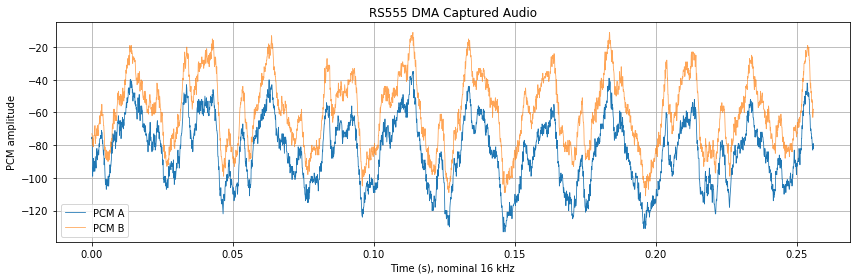

In [13]:

import numpy as np
import matplotlib.pyplot as plt

words = np.fromfile("rs555_audio_frame.bin", dtype="<u4")

a = (words & 0xffff).astype(np.uint16).view(np.int16)
b = (words >> 16).astype(np.uint16).view(np.int16)

for name, ch in [("PCM A", a), ("PCM B", b)]:
    x = ch.astype(np.float64)
    mean = np.mean(x)
    ac_rms = np.sqrt(np.mean((x - mean) ** 2))

    print(name)
    print("  Mean:", round(mean, 2))
    print("  AC RMS:", round(ac_rms, 2))
    print("  Std:", round(np.std(x), 2))
    print("  Min/Max:", np.min(ch), np.max(ch))

t = np.arange(len(words)) / 16000.0

plt.figure(figsize=(12, 4))
plt.plot(t, a, label="PCM A", linewidth=0.8)
plt.plot(t, b, label="PCM B", linewidth=0.8, alpha=0.7)
plt.xlabel("Time (s), nominal 16 kHz")
plt.ylabel("PCM amplitude")
plt.title("RS555 DMA Captured Audio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:

import numpy as np

x = a.astype(np.float64)
y = b.astype(np.float64)

x_ac = x - x.mean()
y_ac = y - y.mean()

correlation = np.corrcoef(x_ac, y_ac)[0, 1]
difference_rms = np.sqrt(np.mean((x - y) ** 2))

print("Channel correlation:", round(correlation, 5))
print("Channel difference RMS:", round(difference_rms, 3))
print("PCM A DC offset:", round(x.mean(), 3))
print("PCM B DC offset:", round(y.mean(), 3))
print("Identical samples:", int(np.count_nonzero(a == b)))


Channel correlation: 0.96276
Channel difference RMS: 24.682
PCM A DC offset: -83.896
PCM B DC offset: -59.928
Identical samples: 0
